# NYSED Report Card Analysis

Correlation and regression analysis of school-level performance against chronic absenteeism, teacher inexperience, teacher certification, per-pupil funding, and charter status, using the cleaned tables from `02_clean_data.ipynb`.

In [1]:
import pandas as pd

df_scores = pd.read_csv("../data/exports/scores.csv", dtype=str)
df_staffing = pd.read_csv("../data/exports/staffing.csv", dtype=str)
df_expend = pd.read_csv("../data/exports/expenditures.csv", dtype=str)
df_chronic = pd.read_csv("../data/exports/chronic_absenteeism.csv", dtype=str)

print(df_scores.shape, df_staffing.shape, df_expend.shape, df_chronic.shape)

(488344, 14) (9470, 35) (9466, 14) (77760, 13)


In [2]:
# Scores: filter to All Students, pivot ELA/Math wide per school/year
scores_all = df_scores[df_scores["SUBGROUP_NAME"] == "All Students"].copy()
scores_all["PER_PROF"] = pd.to_numeric(scores_all["PER_PROF"], errors="coerce")

scores_wide = scores_all.pivot_table(
    index=["INSTITUTION_ID", "YEAR"],
    columns="SUBJECT",
    values="PER_PROF",
    aggfunc="mean"
).reset_index()
scores_wide.columns.name = None
scores_wide = scores_wide.rename(columns={"ELA": "ELA", "Math": "Math"})


In [3]:
# Staffing: All Students rows only, relevant columns
staff_all = df_staffing[df_staffing["SUBGROUP_NAME"] == "All Students"].copy() if "SUBGROUP_NAME" in df_staffing.columns else df_staffing.copy()
staff_all["PER_TEACH_INEXP"] = pd.to_numeric(staff_all["PER_TEACH_INEXP"], errors="coerce")
staff_all["PER_OUT_CERT"] = pd.to_numeric(staff_all["PER_OUT_CERT"], errors="coerce")
staff_cols = staff_all[["INSTITUTION_ID", "YEAR", "PER_TEACH_INEXP", "PER_OUT_CERT"]].drop_duplicates(subset=["INSTITUTION_ID", "YEAR"])


In [4]:

# Expenditures
df_expend["PER_FED_STATE_LOCAL_EXP"] = pd.to_numeric(df_expend["PER_FED_STATE_LOCAL_EXP"], errors="coerce")
expend_cols = df_expend[["INSTITUTION_ID", "YEAR", "PER_FED_STATE_LOCAL_EXP"]].drop_duplicates(subset=["INSTITUTION_ID", "YEAR"])


In [5]:

# Chronic absenteeism: All Students only
chronic_all = df_chronic[df_chronic["SUBGROUP_NAME"] == "All Students"].copy()
chronic_all["ABSENT_RATE"] = pd.to_numeric(chronic_all["ABSENT_RATE"], errors="coerce")
chronic_cols = chronic_all[["INSTITUTION_ID", "YEAR", "ABSENT_RATE"]].drop_duplicates(subset=["INSTITUTION_ID", "YEAR"])


In [6]:

# Merge everything
analysis_df = scores_wide.merge(staff_cols, on=["INSTITUTION_ID", "YEAR"], how="inner")
analysis_df = analysis_df.merge(expend_cols, on=["INSTITUTION_ID", "YEAR"], how="inner")
analysis_df = analysis_df.merge(chronic_cols, on=["INSTITUTION_ID", "YEAR"], how="inner")


In [7]:

# Add CHARTER flag from ENTITY_CD digits 7-8 == "86"
df_institutions = pd.read_csv("../data/exports/institutions.csv", dtype=str)
df_institutions["CHARTER"] = df_institutions["ENTITY_CD"].str[6:8] == "86"
analysis_df = analysis_df.merge(
    df_institutions[["INSTITUTION_ID", "CHARTER", "COUNTY_NAME"]],
    on="INSTITUTION_ID", how="left"
)

print(analysis_df.shape)
analysis_df.head()

(7142, 10)


,INSTITUTION_ID,YEAR,ELA,Math,PER_TEACH_INEXP,PER_OUT_CERT,PER_FED_STATE_LOCAL_EXP,ABSENT_RATE,CHARTER,COUNTY_NAME
0,800000033912,2024,39.5,50.5,17.0,7.0,28024.0,29.4,False,LIVINGSTON
1,800000033912,2025,44.0,39.0,20.0,11.0,29098.0,27.3,False,LIVINGSTON
2,800000033917,2024,38.0,57.5,7.0,4.0,19988.0,10.8,False,LIVINGSTON
3,800000033917,2025,54.5,69.5,14.0,0.0,24242.0,9.6,False,LIVINGSTON
4,800000033920,2024,57.5,42.5,11.0,9.0,36292.0,20.5,False,LIVINGSTON


In [8]:
corr_cols = ["ELA", "Math", "PER_TEACH_INEXP", "PER_OUT_CERT", "PER_FED_STATE_LOCAL_EXP", "ABSENT_RATE"]
analysis_df[corr_cols].corr()

,ELA,Math,PER_TEACH_INEXP,PER_OUT_CERT,PER_FED_STATE_LOCAL_EXP,ABSENT_RATE
ELA,1.000000,0.889976,-0.135266,-0.006075,-0.102627,-0.463289
Math,0.889976,1.000000,-0.171474,-0.071577,-0.138253,-0.527629
PER_TEACH_INEXP,-0.135266,-0.171474,1.000000,0.475636,-0.032306,0.298770
PER_OUT_CERT,-0.006075,-0.071577,0.475636,1.000000,-0.106383,0.333918
PER_FED_STATE_LOCAL_EXP,-0.102627,-0.138253,-0.032306,-0.106383,1.000000,0.145586
ABSENT_RATE,-0.463289,-0.527629,0.298770,0.333918,0.145586,1.000000


In [9]:
from sklearn.linear_model import LinearRegression

reg_df = analysis_df.dropna(subset=["ELA", "PER_TEACH_INEXP", "PER_OUT_CERT", "PER_FED_STATE_LOCAL_EXP", "ABSENT_RATE", "CHARTER"]).copy()
reg_df["CHARTER_NUM"] = reg_df["CHARTER"].astype(int)

X = reg_df[["PER_TEACH_INEXP", "PER_OUT_CERT", "PER_FED_STATE_LOCAL_EXP", "ABSENT_RATE", "CHARTER_NUM"]]
y_ela = reg_df["ELA"]

model_ela = LinearRegression().fit(X, y_ela)

print("R-squared:", model_ela.score(X, y_ela))
for col, coef in zip(X.columns, model_ela.coef_):
    print(f"{col}: {coef:.3f}")

R-squared: 0.27126861560704774
PER_TEACH_INEXP: -0.108
PER_OUT_CERT: 0.063
PER_FED_STATE_LOCAL_EXP: 0.000
ABSENT_RATE: -0.622
CHARTER_NUM: 14.877


In [12]:
reg_df_math = analysis_df.dropna(subset=["Math", "PER_TEACH_INEXP", "PER_OUT_CERT", "PER_FED_STATE_LOCAL_EXP", "ABSENT_RATE", "CHARTER"]).copy()
reg_df_math["CHARTER_NUM"] = reg_df_math["CHARTER"].astype(int)

X_math = reg_df_math[["PER_TEACH_INEXP", "PER_OUT_CERT", "PER_FED_STATE_LOCAL_EXP", "ABSENT_RATE", "CHARTER_NUM"]]
y_math = reg_df_math["Math"]

model_math = LinearRegression().fit(X_math, y_math)

print("R-squared:", model_math.score(X_math, y_math))
for col, coef in zip(X_math.columns, model_math.coef_):
    print(f"{col}: {coef:.3f}")

R-squared: 0.3268499460287906
PER_TEACH_INEXP: -0.117
PER_OUT_CERT: -0.032
PER_FED_STATE_LOCAL_EXP: 0.000
ABSENT_RATE: -0.731
CHARTER_NUM: 19.435


In [13]:
# Rebuild a subgroup-level version: merge ELA scores (by subgroup) with chronic absenteeism (by subgroup)
scores_subgroup = df_scores[df_scores["SUBJECT"] == "ELA"].copy()
scores_subgroup["PER_PROF"] = pd.to_numeric(scores_subgroup["PER_PROF"], errors="coerce")

chronic_subgroup = df_chronic.copy()
chronic_subgroup["ABSENT_RATE"] = pd.to_numeric(chronic_subgroup["ABSENT_RATE"], errors="coerce")

merged_subgroup = scores_subgroup.merge(
    chronic_subgroup[["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME", "ABSENT_RATE"]],
    on=["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME"],
    how="inner"
)

subgroup_corr_ela = merged_subgroup.groupby("SUBGROUP_NAME").apply(
    lambda g: g["ABSENT_RATE"].corr(g["PER_PROF"])
).sort_values()

print(subgroup_corr_ela)

SUBGROUP_NAME
Multiracial                                       -0.644402
Asian or Native Hawaiian/Other Pacific Islander   -0.505533
American Indian or Alaska Native                  -0.460878
White                                             -0.432623
All Students                                      -0.422987
Black or African American                         -0.300971
Hispanic or Latino                                -0.290121
Economically Disadvantaged                        -0.208734
Students with Disabilities                        -0.162611
English Language Learner                          -0.117148
dtype: float64


In [14]:
scores_subgroup_math = df_scores[df_scores["SUBJECT"] == "Math"].copy()
scores_subgroup_math["PER_PROF"] = pd.to_numeric(scores_subgroup_math["PER_PROF"], errors="coerce")

merged_subgroup_math = scores_subgroup_math.merge(
    chronic_subgroup[["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME", "ABSENT_RATE"]],
    on=["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME"],
    how="inner"
)

subgroup_corr_math = merged_subgroup_math.groupby("SUBGROUP_NAME").apply(
    lambda g: g["ABSENT_RATE"].corr(g["PER_PROF"])
).sort_values()

print(subgroup_corr_math)

SUBGROUP_NAME
Multiracial                                       -0.651725
Asian or Native Hawaiian/Other Pacific Islander   -0.592272
White                                             -0.479291
All Students                                      -0.469365
American Indian or Alaska Native                  -0.414612
Hispanic or Latino                                -0.344094
Black or African American                         -0.325986
Economically Disadvantaged                        -0.292125
English Language Learner                          -0.230054
Students with Disabilities                        -0.223293
dtype: float64


In [15]:
staff_subgroup = df_staffing.copy()
staff_subgroup["PER_TEACH_INEXP"] = pd.to_numeric(staff_subgroup["PER_TEACH_INEXP"], errors="coerce")

if "SUBGROUP_NAME" in staff_subgroup.columns:
    merged_staff_ela = scores_subgroup.merge(
        staff_subgroup[["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME", "PER_TEACH_INEXP"]],
        on=["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME"],
        how="inner"
    )
else:
    merged_staff_ela = scores_subgroup.merge(
        staff_subgroup[["INSTITUTION_ID", "YEAR", "PER_TEACH_INEXP"]],
        on=["INSTITUTION_ID", "YEAR"],
        how="inner"
    )

subgroup_corr_staff = merged_staff_ela.groupby("SUBGROUP_NAME").apply(
    lambda g: g["PER_TEACH_INEXP"].corr(g["PER_PROF"])
).sort_values()

print(subgroup_corr_staff)

SUBGROUP_NAME
Multiracial                                       -0.233621
White                                             -0.131966
Asian or Native Hawaiian/Other Pacific Islander   -0.109465
American Indian or Alaska Native                  -0.108395
All Students                                      -0.095530
Female                                            -0.094774
Male                                              -0.082884
Hispanic or Latino                                -0.013322
Economically Disadvantaged                         0.020177
Students with Disabilities                         0.039933
Black or African American                          0.094626
English Language Learner                           0.099541
dtype: float64


In [16]:
expend_subgroup = df_expend.copy()
expend_subgroup["PER_FED_STATE_LOCAL_EXP"] = pd.to_numeric(expend_subgroup["PER_FED_STATE_LOCAL_EXP"], errors="coerce")

if "SUBGROUP_NAME" in expend_subgroup.columns:
    merged_expend_ela = scores_subgroup.merge(
        expend_subgroup[["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME", "PER_FED_STATE_LOCAL_EXP"]],
        on=["INSTITUTION_ID", "YEAR", "SUBGROUP_NAME"],
        how="inner"
    )
else:
    merged_expend_ela = scores_subgroup.merge(
        expend_subgroup[["INSTITUTION_ID", "YEAR", "PER_FED_STATE_LOCAL_EXP"]],
        on=["INSTITUTION_ID", "YEAR"],
        how="inner"
    )

subgroup_corr_expend = merged_expend_ela.groupby("SUBGROUP_NAME").apply(
    lambda g: g["PER_FED_STATE_LOCAL_EXP"].corr(g["PER_PROF"])
).sort_values()

print(subgroup_corr_expend)

SUBGROUP_NAME
American Indian or Alaska Native                  -0.418781
English Language Learner                          -0.155627
Black or African American                         -0.131891
Hispanic or Latino                                -0.131223
Male                                              -0.111576
Female                                            -0.108574
All Students                                      -0.104830
Economically Disadvantaged                        -0.084736
Students with Disabilities                        -0.054786
Asian or Native Hawaiian/Other Pacific Islander    0.035533
White                                              0.086807
Multiracial                                        0.119638
dtype: float64


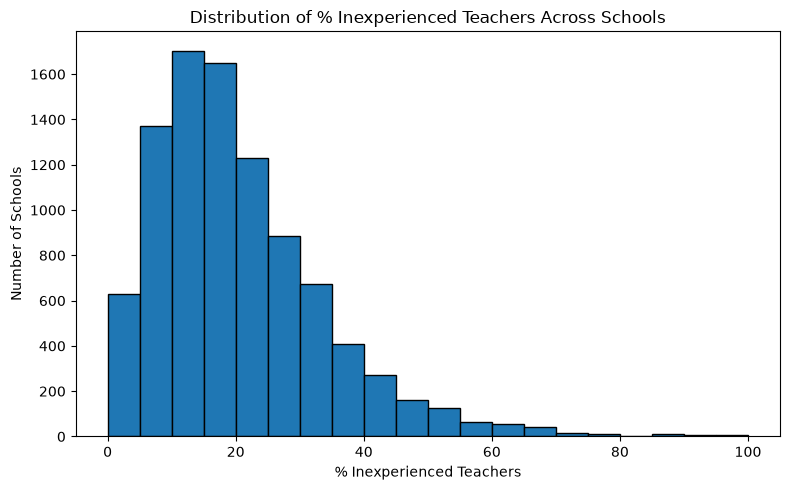

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_staffing["PER_TEACH_INEXP"].dropna().astype(float), bins=20, edgecolor="black")
plt.title("Distribution of % Inexperienced Teachers Across Schools")
plt.xlabel("% Inexperienced Teachers")
plt.ylabel("Number of Schools")
plt.tight_layout()
plt.show()

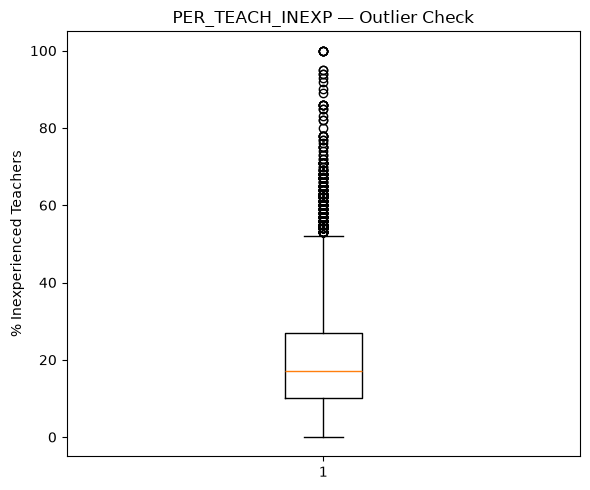

In [18]:
plt.figure(figsize=(6, 5))
plt.boxplot(df_staffing["PER_TEACH_INEXP"].dropna().astype(float))
plt.title("PER_TEACH_INEXP — Outlier Check")
plt.ylabel("% Inexperienced Teachers")
plt.tight_layout()
plt.show()

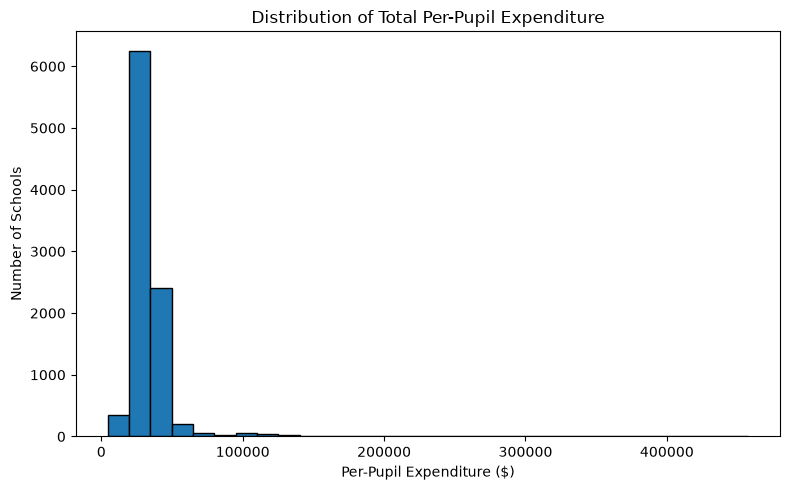

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(df_expend["PER_FED_STATE_LOCAL_EXP"].dropna().astype(float), bins=30, edgecolor="black")
plt.title("Distribution of Total Per-Pupil Expenditure")
plt.xlabel("Per-Pupil Expenditure ($)")
plt.ylabel("Number of Schools")
plt.tight_layout()
plt.show()


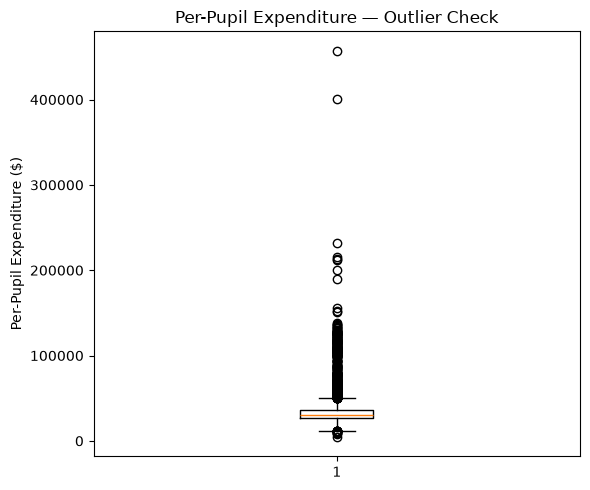

count      9426.000000
mean      33048.279970
std       14893.884968
min        4470.000000
25%       26422.500000
50%       30869.000000
75%       35975.500000
max      457366.000000
Name: PER_FED_STATE_LOCAL_EXP, dtype: float64


In [20]:

plt.figure(figsize=(6, 5))
plt.boxplot(df_expend["PER_FED_STATE_LOCAL_EXP"].dropna().astype(float))
plt.title("Per-Pupil Expenditure — Outlier Check")
plt.ylabel("Per-Pupil Expenditure ($)")
plt.tight_layout()
plt.show()

print(df_expend["PER_FED_STATE_LOCAL_EXP"].astype(float).describe())

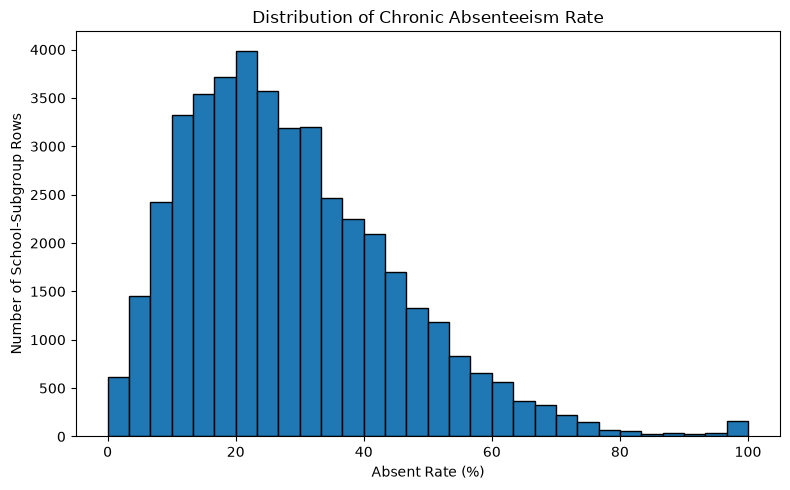

count    43545.000000
mean        28.561449
std         16.481556
min          0.000000
25%         16.200000
50%         25.800000
75%         38.300000
max        100.000000
Name: ABSENT_RATE, dtype: float64


In [21]:
plt.figure(figsize=(8, 5))
plt.hist(df_chronic["ABSENT_RATE"].dropna().astype(float), bins=30, edgecolor="black")
plt.title("Distribution of Chronic Absenteeism Rate")
plt.xlabel("Absent Rate (%)")
plt.ylabel("Number of School-Subgroup Rows")
plt.tight_layout()
plt.show()

print(df_chronic["ABSENT_RATE"].astype(float).describe())

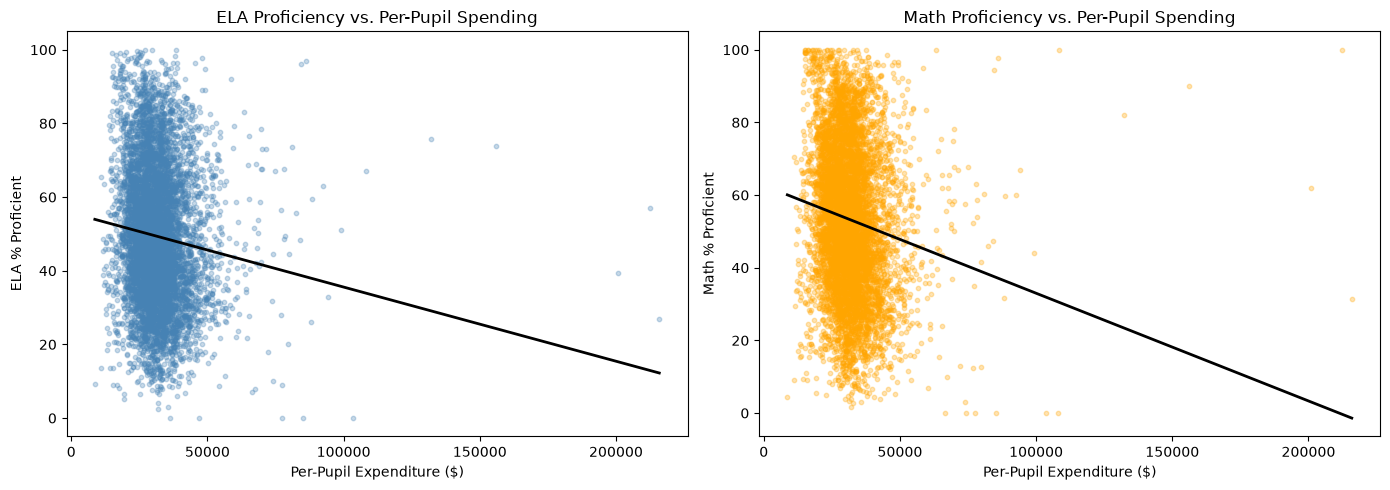

In [23]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, subject, color in zip(axes, ["ELA", "Math"], ["steelblue", "orange"]):
    data = analysis_df.dropna(subset=["PER_FED_STATE_LOCAL_EXP", subject])
    x = data["PER_FED_STATE_LOCAL_EXP"]
    y = data[subject]

    ax.scatter(x, y, alpha=0.3, s=10, color=color)

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept, color="black", linewidth=2)

    ax.set_title(f"{subject} Proficiency vs. Per-Pupil Spending")
    ax.set_xlabel("Per-Pupil Expenditure ($)")
    ax.set_ylabel(f"{subject} % Proficient")

plt.tight_layout()
plt.savefig("../images/funding_vs_proficiency.png", dpi=150)
plt.show()

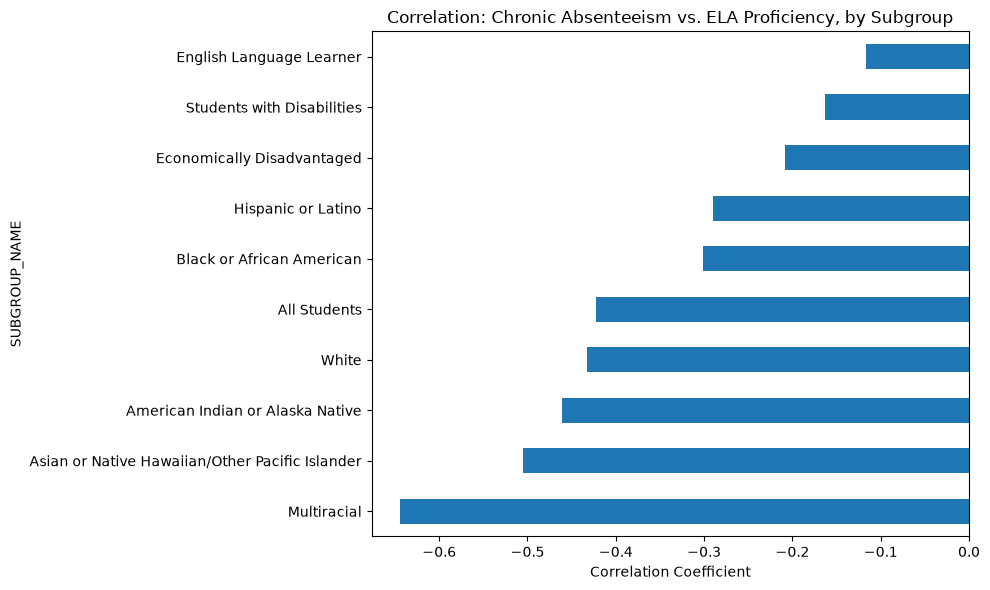

In [24]:
plt.figure(figsize=(10, 6))
subgroup_corr_ela.plot(kind="barh")
plt.title("Correlation: Chronic Absenteeism vs. ELA Proficiency, by Subgroup")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.savefig("../images/subgroup_correlation_absenteeism.png", dpi=150)
plt.show()

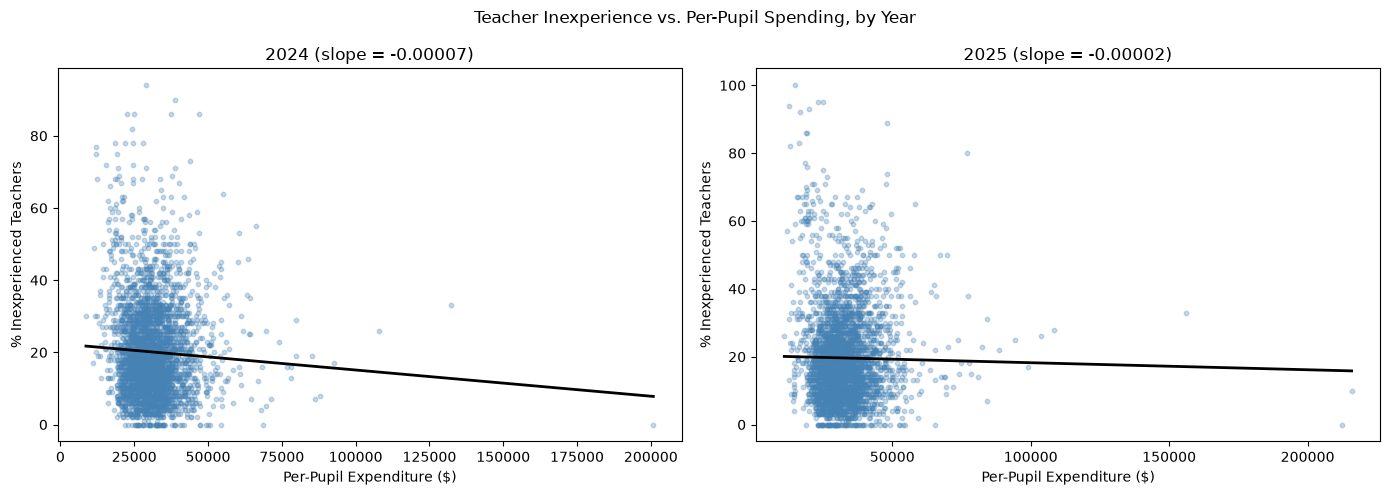

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, yr in zip(axes, sorted(analysis_df["YEAR"].unique())):
    data = analysis_df[analysis_df["YEAR"] == yr].dropna(subset=["PER_FED_STATE_LOCAL_EXP", "PER_TEACH_INEXP"])
    x = data["PER_FED_STATE_LOCAL_EXP"]
    y = data["PER_TEACH_INEXP"]

    ax.scatter(x, y, alpha=0.3, s=10, color="steelblue")

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept, color="black", linewidth=2)

    ax.set_title(f"{yr} (slope = {slope:.5f})")
    ax.set_xlabel("Per-Pupil Expenditure ($)")
    ax.set_ylabel("% Inexperienced Teachers")

plt.suptitle("Teacher Inexperience vs. Per-Pupil Spending, by Year")
plt.tight_layout()
plt.savefig("../images/funding_vs_teacher_inexperience.png", dpi=150)
plt.show()

## Summary of Findings

- **Chronic absenteeism** is the strongest predictor of proficiency (ELA r = -0.46, Math r = -0.53), stronger than funding or teacher experience.
- **Charter status**, once controlled for funding/staffing/absenteeism in a multi-variable regression, is associated with *higher* proficiency (+14.9 ELA, +19.4 Math) — the opposite of the raw, uncontrolled comparison.
- **Per-pupil funding** has close to zero independent effect on proficiency once other factors are controlled (regression coefficient ≈ 0.000 for both subjects), consistent with funding following need rather than funding driving outcomes.
- **Subgroup patterns vary substantially**: the absenteeism-performance link is weakest for English Language Learners and Students with Disabilities, and strongest for Multiracial and Asian/Pacific Islander students — the opposite of what was initially expected.
- The teacher-inexperience correlation **flips sign** for several subgroups (Economically Disadvantaged, Students with Disabilities, Black/African American, English Language Learner show a slight *positive* correlation), likely confounded rather than causal.
- The funding correlation is strongly negative for American Indian/Alaska Native students (-0.42) and the only two subgroups with a positive funding correlation are White and Multiracial - consistent with funding-follows-need.